In [ ]:
# packages 
import numpy as np
import pandas as pd
import cvxpy as cp
import matplotlib.pyplot as plt
import networkx as nx 

from power_system_data import PowerSystemData
from power_system_data_time import PowerSystemDataTime
#data2 = PowerSystemDataTime.from_csv('../data/base_case')   # read everything from CSV files
#data2


In [3]:
# import data of the network : topologies, capacities, RES, load and Generation scenario for 1 time step 
data = PowerSystemData()

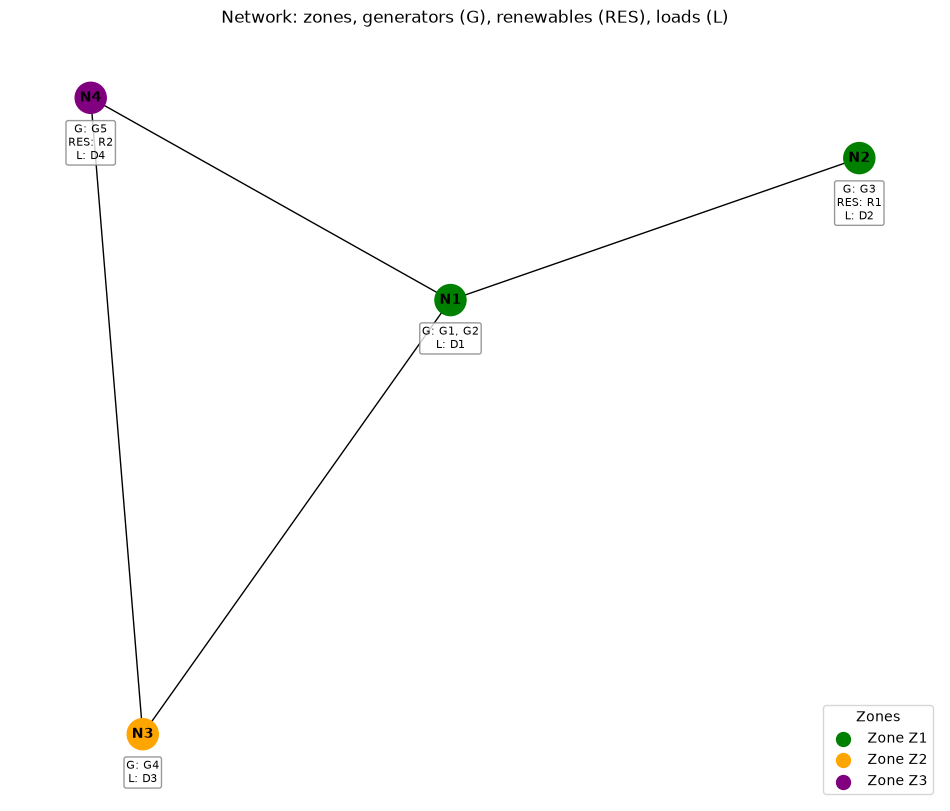

In [4]:
# Basic vizualization
G = nx.Graph()

for n in data.NODES:
    G.add_node(n,
               zone=data.node_zone[n],
               generators=data.generators_per_node.get(n, []),
               loads=data.loads_per_node.get(n, []),
               renewables=data.renewables_per_node.get(n, []))

for (n, m) in data.lines:
    G.add_edge(n, m, capacity=data.line_capacity_per_line[(n, m)])

# Draw the network with nodes coloured by zone
zone_colors = {'Z1': 'green', 'Z2': 'orange', 'Z3': 'purple'}

fig, ax = plt.subplots(figsize=(12, 10))
pos = nx.spring_layout(G, seed=42)   # fixed seed -> same layout every run

# One colour per node, in the same order as G.nodes
node_colors = [zone_colors[data.node_zone[n]] for n in G.nodes]

nx.draw(G, pos, ax=ax, with_labels=True, node_color=node_colors,
        node_size=500, font_size=10, font_weight='bold')

# Generators / renewables / loads written under each node
def asset_text(n):
    a = G.nodes[n]
    parts = []
    if a['generators']: parts.append("G: "   + ", ".join(map(str, a['generators'])))
    if a['renewables']: parts.append("RES: " + ", ".join(map(str, a['renewables'])))
    if a['loads']:      parts.append("L: "   + ", ".join(map(str, a['loads'])))
    return "\n".join(parts)

for n, (x, y) in pos.items():
    txt = asset_text(n)
    if txt:
        ax.annotate(txt, (x, y), xytext=(0, -18), textcoords='offset points',
                    ha='center', va='top', fontsize=8,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='grey', alpha=0.8))

# Zone legend
for zone, color in zone_colors.items():
    ax.scatter([], [], c=color, s=100, label=f"Zone {zone}")
ax.legend(title="Zones", loc="lower right")

ax.set_title("Network: zones, generators (G), renewables (RES), loads (L)")
plt.show()


In [5]:
for key, value in data.__dict__.items():
    print(f"{key}: {value}")


N_GENERATORS: 5
N_LOADS: 4
N_NODES: 4
N_ZONES: 3
N_SCENARIOS: 2
N_RES: 2
GENERATORS: ['G1', 'G2', 'G3', 'G4', 'G5']
LOADS: ['D1', 'D2', 'D3', 'D4']
NODES: ['N1', 'N2', 'N3', 'N4']
ZONES: ['Z1', 'Z2', 'Z3']
SCENARIOS: ['S1', 'S2']
RENEWABLES: ['R1', 'R2']
S_BASE_MVA: 100.0
V_BASE_KV: {'N1': 230.0, 'N2': 230.0, 'N3': 230.0, 'N4': 230.0}
time_step: 1
slack_bus: N1
nodes_per_zone: {'Z1': ['N1', 'N2'], 'Z2': ['N3'], 'Z3': ['N4']}
connections_per_node: {'N1': ['N2', 'N3', 'N4'], 'N2': ['N1'], 'N3': ['N1', 'N4'], 'N4': ['N1', 'N3']}
generators_per_node: {'N1': ['G1', 'G2'], 'N2': ['G3'], 'N3': ['G4'], 'N4': ['G5']}
loads_per_node: {'N1': ['D1'], 'N2': ['D2'], 'N3': ['D3'], 'N4': ['D4']}
renewables_per_node: {'N1': [], 'N2': ['R1'], 'N3': [], 'N4': ['R2']}
gen_linear_cost_coeff: {'G1': 20, 'G2': 30, 'G3': 40, 'G4': 80, 'G5': 70}
gen_down_deviation_cost_coeff: {'G1': 10, 'G2': 8, 'G3': 2, 'G4': 2, 'G5': 2}
gen_up_deviation_cost_coeff: {'G1': 2, 'G2': 0, 'G3': 2, 'G4': 2, 'G5': 2}
gen_max_capaci

In [6]:
def solve_base_case(data: PowerSystemData, load=None, res=None, solver=cp.GUROBI, verbose=False):
    """Day-ahead nodal dispatch (DC-OPF via PTDF) at a given load and renewable level.

    load: vector over data.LOADS;      defaults to data.expected_DA_load_vec.
    res:  vector over data.RENEWABLES; defaults to data.expected_DA_res_vec.
    """
    d = data.expected_DA_load_vec if load is None else np.asarray(load, float)
    r = data.expected_DA_res_vec if res is None else np.asarray(res, float)

    g = cp.Variable(len(data.GENERATORS), nonneg=True )                # generator output
    C = cp.Variable(len(data.RENEWABLES), nonneg=True)                # renewable curtailment
    I = cp.Variable(len(data.NODES))                     # nodal net injection
    f = cp.Variable(len(data.lines))                     # line flows

    nodal_balance = I == data.M_ng @ g + data.M_nr @ (r - C) - data.M_nd @ d   # G + r - C - d = P
    cons = [nodal_balance,
            f == data.PTDF @ I,
            cp.sum(I) == 0,
            g >= data.gen_min_vec, g <= data.gen_max_vec,
            C >= 0, C <= r, # C>0 redondant constraint 
            f <= data.line_cap_vec, f >= -data.line_cap_vec]
    prob = cp.Problem(cp.Minimize(data.gen_cost_vec @ g
                                  + data.res_curtailment_cost_vec @ C), cons)
    prob.solve(solver=solver, verbose=verbose)
    assert prob.status == cp.OPTIMAL, f"base case: {prob.status}"

    I_bc = I.value
    return dict(g=pd.Series(g.value, index=data.GENERATORS),
                C=pd.Series(C.value, index=data.RENEWABLES),
                P=pd.Series(I_bc, index=data.NODES),
                f=pd.Series(f.value, index=data.lines),
                NP=pd.Series(data.M_zn @ I_bc, index=data.ZONES),   # zonal net position
                LMP=pd.Series(nodal_balance.dual_value, index=data.NODES),  # nodal price
                cost=prob.value, 
                status = prob.status)

In [7]:
bc = solve_base_case(data, verbose=True)

(CVXPY) Oct 16 04:32:21 PM: Your problem has 15 variables, 31 constraints, and 0 parameters.
(CVXPY) Oct 16 04:32:21 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 16 04:32:21 PM: DCP verification time: 0.0003 seconds.
(CVXPY) Oct 16 04:32:21 PM: Expression tree has 4 nodes.
(CVXPY) Oct 16 04:32:21 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 16 04:32:21 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 16 04:32:21 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 16 04:32:21 PM: Compiling problem (target solver=GUROBI).
(CVXPY) Oct 16 04:32:21 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> EliminateZeroSized -> ConeMatrixStuffing -> GUROBI
(CVXPY) Oct 16 04:32:21 PM: Applying reduction Dcp2Cone
(CVXPY) Oct 16 04:32:21 PM: Applying reduction CvxAttr2Constr
(CVXPY) Oct 16 04:32:21 PM: Apply

                                     CVXPY                                     
                                     v1.9.3                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
Set parameter Username
Set parameter LicenseID to value 2874629
Academic license - for non-commercial use only - expires 2027-10-14
Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 23.4.0 23E214)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors,

(CVXPY) Oct 16 04:32:21 PM: Problem status: optimal
(CVXPY) Oct 16 04:32:21 PM: Optimal value: 1.381e+04
(CVXPY) Oct 16 04:32:21 PM: Compilation took 1.755e-02 seconds
(CVXPY) Oct 16 04:32:21 PM: Solver (including time spent in interface) took 1.456e-02 seconds


-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------


In [8]:
for k, v in bc.items():
    print(f"{k}:\n{v}\n")

g:
G1    40.0
G2    60.0
G3     0.0
G4    60.0
G5    90.0
dtype: float64

C:
R1    110.0
R2      0.0
dtype: float64

P:
N1    50.0
N2    30.0
N3   -90.0
N4    10.0
dtype: float64

f:
(N1, N2)   -30.000000
(N1, N3)    56.666667
(N1, N4)    23.333333
(N3, N4)   -33.333333
dtype: float64

NP:
Z1    80.0
Z2   -90.0
Z3    10.0
dtype: float64

LMP:
N1    80.0
N2    -1.0
N3    80.0
N4    80.0
dtype: float64

cost:
13810.0

status:
optimal



In [9]:
bc["g"].values

array([40., 60.,  0., 60., 90.])

<Axes: title={'left': 'Base case — total cost 13810.0 €   (arrow = flow direction, width = loading, red = binding)'}>

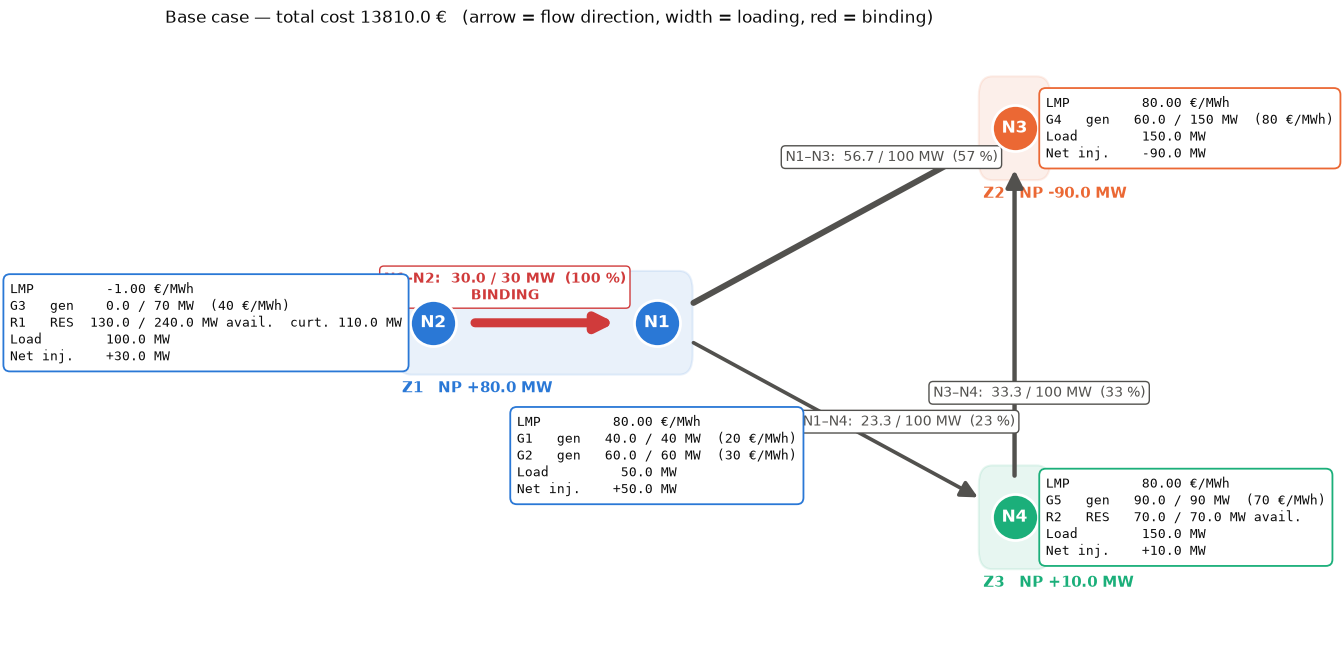

In [10]:
plot_network(data, bc)


In [11]:
data.mapping_zones
np.array([[1 if n in nodes else 0 for n in data.NODES] for zone, nodes in data.nodes_per_zone.items()])
data.PTDF

array([[ 0.        , -1.        ,  0.        ,  0.        ],
       [ 0.        ,  0.        , -0.66666667, -0.33333333],
       [ 0.        ,  0.        , -0.33333333, -0.66666667],
       [ 0.        ,  0.        ,  0.33333333, -0.33333333]])

In [12]:
def select_cne(data, threshold=0.05):
    """CNEs = all inter-zonal lines + internal lines with max z2z PTDF >= threshold."""
    Z = len(data.ZONES)
    z2z = np.array([np.abs(data.PTDF_zonal[:, a] - data.PTDF_zonal[:, b])
                    for a in range(Z) for b in range(Z) if a < b]).max(axis=0)   # one value per line
    return [l for k, l in enumerate(data.lines)
            if l in data.inter_lines or z2z[k] >= threshold]
CNE = select_cne(data, 0.05)
CNE

[('N1', 'N2'), ('N1', 'N3'), ('N1', 'N4'), ('N3', 'N4')]

In [13]:
data.GSK

array([[0.21276596, 0.        , 0.        ],
       [0.78723404, 0.        , 0.        ],
       [0.        , 1.        , 0.        ],
       [0.        , 0.        , 1.        ]])

In [14]:
def build_flow_based(data, cne_lines):
    """Flow-based domain: zPTDF @ NP <= RAM (both directions of each CNE)."""
    L = len(data.lines)
    idx = [data.lines.index(l) for l in cne_lines]
    M = np.eye(L)[idx]                         # K x L  : CNE selection

    K = len(idx)
    Fmax = M @ data.line_cap_vec               # K     : capacity of each CNE
    RAM = np.tile(0.7 * Fmax, 2)               

    S = np.vstack([np.eye(K), -np.eye(K)])     # 2K x K : direction

    zPTDF = S @ M @ data.PTDF_zonal            # 2K x Z  (= S M PTDF GSK)


    return dict(zPTDF=zPTDF, cne_lines=cne_lines, RAM = RAM, M=M, S=S)
 
parameters = build_flow_based(data, CNE)
parameters["M"]

array([[1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 0., 1.]])

In [15]:
parameters["cne_lines"]

[('N1', 'N2'), ('N1', 'N3'), ('N1', 'N4'), ('N3', 'N4')]

In [16]:
from statistics import NormalDist

def da_zonal_clearing(data: PowerSystemData, bc, load=None, res=None, solver=cp.GUROBI, verbose=False, parameters=None, sigma_rel=0.10,Sigma= None, eps = 0.05, fb=None, d=None, r_avail=None, G_ref=None, NP_ref=None, RAM=None):
    # Input
    d = data.expected_DA_load_vec if load is None else np.asarray(load, float)
    r = data.expected_DA_res_vec if res is None else np.asarray(res, float)

    g = bc["g"].values  # Generator output from BC
    C = bc["C"].values  # Renewable curtailment

    # Variables
    NP_da = cp.Variable(len(data.ZONES))
    G_da = cp.Variable(len(data.GENERATORS), nonneg = True)
    C_da = cp.Variable(len(data.RENEWABLES), nonneg = True)
    alpha = cp.Variable(len(data.GENERATORS), nonneg=True)    # participation factors


    # Parameters
    m = parameters["M"]
    zPDTF = parameters["zPTDF"]

    if Sigma is None:
        Sigma = np.diag((sigma_rel * r) ** 2)
    Sh = np.linalg.cholesky(Sigma + 1e-12 * np.eye(len(data.RENEWABLES)))   # Sigma = Sh Sh^T
    sig_s = np.linalg.norm(Sh.T @ np.ones(data.N_RES))             # std of e^T omega
    z_gen = NormalDist().inv_cdf(1 - eps )             




    balance = NP_da == data.M_zg @ G_da + data.M_zr @ (r - C_da ) - data.M_zd @ d
    cons = [balance , C_da >= 0, C_da <= r,    
            G_da + z_gen * sig_s * alpha <= data.gen_max_vec,     # [CC] upper
            G_da - z_gen * sig_s * alpha >= 0, # [CC] lower]
            zPDTF @ NP_da <= parameters["RAM"] , 
            #zPDTF @ NP_da <= np.tile( parameters["M"]@ data.line_cap_vec  , 2)  , 


            cp.sum(NP_da) == 0,
            cp.sum(alpha) ==1 
            ]                   

    


    prob = cp.Problem(cp.Minimize(data.gen_cost_vec @ G_da  + data.res_curtailment_cost_vec @ C_da), cons)
    prob.solve(solver=solver, verbose=verbose)
    #assert prob.status == cp.OPTIMAL, prob.status

    return dict(G=pd.Series(G_da.value, index=data.GENERATORS),
                C=pd.Series(C_da.value, index=data.RENEWABLES),
                NP=pd.Series(NP_da.value, index=data.ZONES),
                alpha=pd.Series(alpha.value, index=data.GENERATORS),
                price=pd.Series(balance.dual_value, index=data.ZONES),   # zonal price
                cost=prob.value)





In [17]:
da = da_zonal_clearing(data, bc, parameters=parameters, Sigma = None, sigma_rel=0.1 , verbose=True)

(CVXPY) Oct 16 04:35:12 PM: Your problem has 15 variables, 27 constraints, and 0 parameters.
(CVXPY) Oct 16 04:35:12 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Oct 16 04:35:12 PM: DCP verification time: 0.0008 seconds.
(CVXPY) Oct 16 04:35:12 PM: Expression tree has 6 nodes.
(CVXPY) Oct 16 04:35:12 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Oct 16 04:35:12 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Oct 16 04:35:12 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Oct 16 04:35:12 PM: Compiling problem (target solver=GUROBI).
(CVXPY) Oct 16 04:35:12 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> EliminateZeroSized -> ConeMatrixStuffing -> GUROBI
(CVXPY) Oct 16 04:35:12 PM: Applying reduction Dcp2Cone
(CVXPY) Oct 16 04:35:12 PM: Applying reduction CvxAttr2Constr
(CVXPY) Oct 16 04:35:12 PM: Apply

                                     CVXPY                                     
                                     v1.9.3                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
Set parameter OutputFlag to value 1
Set parameter QCPDual to value 1
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 23.4.0 23E214)

CPU model: Apple M2
Thread count: 8 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
QCPDual  1

Optimize a model with 27 rows, 15 columns and 56 nonzeros (Min)
Model fi

(CVXPY) Oct 16 04:35:12 PM: Problem status: optimal
(CVXPY) Oct 16 04:35:12 PM: Optimal value: 1.552e+04
(CVXPY) Oct 16 04:35:12 PM: Compilation took 2.539e-02 seconds
(CVXPY) Oct 16 04:35:12 PM: Solver (including time spent in interface) took 2.461e-02 seconds


-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------


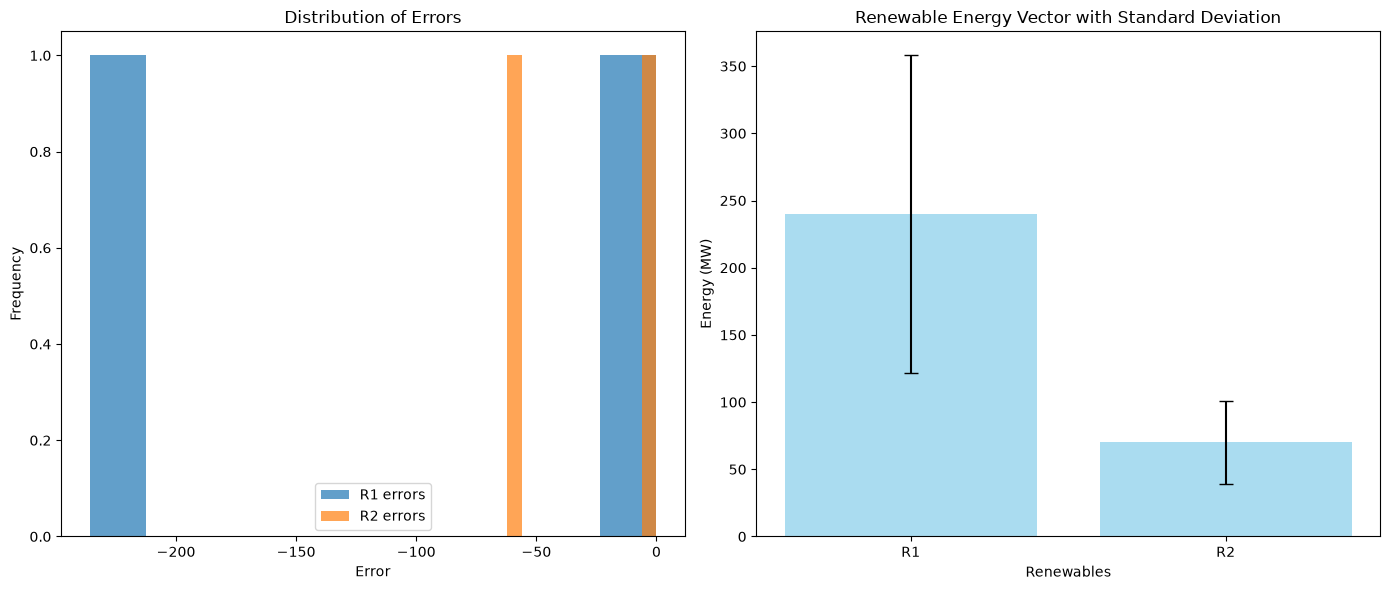

In [18]:
# Extract the renewable energy forecast error distribution
res_scenarios = data.res_scenarios
expected_res = data.expected_DA_res

# Calculate errors for each renewable
errors = {res: [res_scenarios[res][sc] - expected_res[res] for sc in data.SCENARIOS]
          for res in data.RENEWABLES}

# Plot the distribution of errors
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

for res, err in errors.items():
    ax[0].hist(err, bins=10, alpha=0.7, label=f"{res} errors")
ax[0].set_title("Distribution of Errors")
ax[0].set_xlabel("Error")
ax[0].set_ylabel("Frequency")
ax[0].legend()

# Plot the renewable energy vector with its standard deviation
res_values = [expected_res[res] for res in data.RENEWABLES]
std_dev = [np.std(errors[res]) for res in data.RENEWABLES]

ax[1].bar(data.RENEWABLES, res_values, yerr=std_dev, capsize=5, alpha=0.7, color='skyblue')
ax[1].set_title("Renewable Energy Vector with Standard Deviation")
ax[1].set_xlabel("Renewables")
ax[1].set_ylabel("Energy (MW)")

plt.tight_layout()
plt.show()

In [19]:
# Compare generator outputs
print("Generator Outputs:")
print("Base Case (bc):")
print(bc["g"])
print("\nDay-Ahead Clearing (da):")
print(da["G"])

# Compare renewable curtailments
print("\nRenewable Curtailments:")
print("Base Case (bc):")
print(bc["C"])
print("\nDay-Ahead Clearing (da):")
print(da["C"])

# Compare nodal net injections
print("\nNodal Net Injections:")
print("Base Case (bc):")
print(bc["P"])
print("\nDay-Ahead Clearing (da):")
print(da["NP"])

# Compare nodal prices
print("\nNodal Prices:")
print("Base Case (bc):")
print(bc["LMP"])
print("\nDay-Ahead Clearing (da):")
print(da["price"])

# Compare zonal net positions
print("\nZonal Net Positions:")
print("Base Case (bc):")
print(bc["NP"])
print("\nDay-Ahead Clearing (da):")
print(da["NP"])

# Compare total load
print("\nTotal Load:")
print(f"Base Case (bc): {sum(data.expected_DA_load.values())}")
print(f"Day-Ahead Clearing (da): {sum(data.expected_DA_load.values())}")

# Compare total generation
print("\nTotal Generation genrators:")
print(f"Base Case (bc): {bc['g'].sum()}")
print(f"Day-Ahead Clearing (da): {da['G'].sum()}")
print("\nTotal Generation RES:")
print(f"Base Case (bc): {bc['C'].sum()}")
print(f"Day-Ahead Clearing (da): {da['C'].sum()}")
d = data.expected_DA_load_vec
r = data.expected_DA_res_vec

for name, res_ in [("BC", bc), ("DA", da)]:
    G = res_["g"] if "g" in res_ else res_["G"]
    C = res_["C"]
    print(f"{name}: G={G.sum():8.2f}  RES injected={(r - C).sum():8.2f}  "
          f"curtailed={C.sum():8.2f}  total={G.sum() + (r - C).sum():8.2f}  load={d.sum():8.2f}")


# Compare costs
print("\nTotal Costs:")
print(f"Base Case (bc): {bc['cost']}")
print(f"Day-Ahead Clearing (da): {da['cost']}")

Generator Outputs:
Base Case (bc):
G1    40.0
G2    60.0
G3     0.0
G4    60.0
G5    90.0
dtype: float64

Day-Ahead Clearing (da):
G1      4.445665
G2      0.000000
G3      0.000000
G4    113.324324
G5     90.000000
dtype: float64

Renewable Curtailments:
Base Case (bc):
R1    110.0
R2      0.0
dtype: float64

Day-Ahead Clearing (da):
R1    67.769989
R2     0.000000
dtype: float64

Nodal Net Injections:
Base Case (bc):
N1    50.0
N2    30.0
N3   -90.0
N4    10.0
dtype: float64

Day-Ahead Clearing (da):
Z1    26.675676
Z2   -36.675676
Z3    10.000000
dtype: float64

Nodal Prices:
Base Case (bc):
N1    80.0
N2    -1.0
N3    80.0
N4    80.0
dtype: float64

Day-Ahead Clearing (da):
Z1     -1.0
Z2    101.0
Z3    101.0
dtype: float64

Zonal Net Positions:
Base Case (bc):
Z1    80.0
Z2   -90.0
Z3    10.0
dtype: float64

Day-Ahead Clearing (da):
Z1    26.675676
Z2   -36.675676
Z3    10.000000
dtype: float64

Total Load:
Base Case (bc): 450
Day-Ahead Clearing (da): 450

Total Generation genrato

In [20]:
r, d = data.expected_DA_res_vec, data.expected_DA_load_vec
P_da = data.M_ng @ da["G"].values + data.M_nr @ (r - da["C"].values) - data.M_nd @ d
f_da = data.PTDF @ P_da
print(pd.DataFrame({"f_DA": f_da, "f_BC": bc["f"].values, "cap": data.line_cap_vec,
                    "overload": np.abs(f_da) - data.line_cap_vec}, index=data.lines).round(2))


           f_DA   f_BC    cap  overload
(N1, N2) -72.23 -30.00   30.0     42.23
(N1, N3)  21.12  56.67  100.0    -78.88
(N1, N4)   5.56  23.33  100.0    -94.44
(N3, N4) -15.56 -33.33  100.0    -84.44


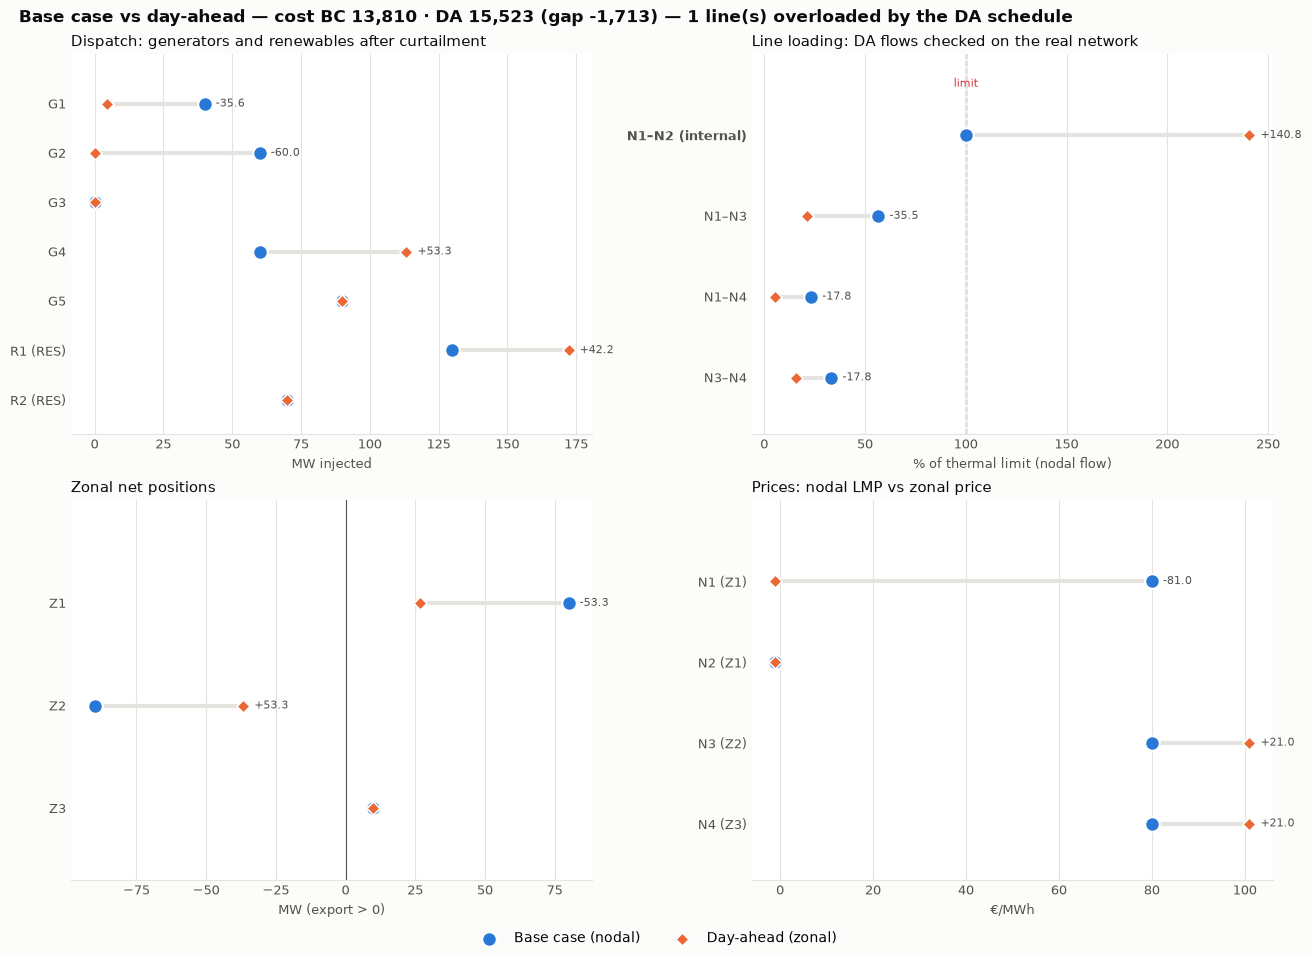

In [21]:
import numpy as np
import matplotlib.pyplot as plt

BC_COLOR, DA_COLOR = "#2a78d6", "#eb6834"      # fixed identity: BC = blue, DA = orange
INK, INK_2, GRID, ALERT = "#0b0b0b", "#52514e", "#e4e3df", "#d03b3b"


def _dumbbell(ax, labels, bc, da, unit, limit=None, alert=None):
    """One row per item: grey connector + BC dot + DA dot. alert: bool mask -> red label."""
    y = np.arange(len(labels))[::-1]
    for yi, b, d in zip(y, bc, da):
        ax.plot([b, d], [yi, yi], color=GRID, lw=3, zorder=1, solid_capstyle="round")
    ax.scatter(bc, y, s=110, color=BC_COLOR, zorder=3, edgecolor="white", linewidth=1.5, label="Base case (nodal)")
    ax.scatter(da, y, s=45, marker="D", color=DA_COLOR, zorder=4, edgecolor="white", linewidth=1.2,
               label="Day-ahead (zonal)")             # smaller diamond on top: both stay visible when equal
    for yi, b, d in zip(y, bc, da):                      # label only the delta, only if it matters
        delta = d - b
        if abs(delta) > 1e-3 * max(1, np.abs(np.r_[bc, da]).max()):
            ax.annotate(f"{delta:+.1f}", (max(b, d), yi), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=8, color=INK_2)
    if limit is not None:
        ax.axvline(limit, color=ALERT, lw=1, ls="--", zorder=0)
        ax.text(limit, y.max() + 0.6, "limit", color=ALERT, fontsize=8, ha="center")
    ax.set_yticks(y, labels)
    if alert is not None:
        for tick, a in zip(ax.get_yticklabels(), alert):
            if a:
                tick.set_color(ALERT); tick.set_fontweight("bold")
    ax.set_xlabel(unit, color=INK_2, fontsize=9)
    ax.set_ylim(y.min() - 0.7, y.max() + 1.0)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=INK_2, length=0, labelsize=9)


def plot_bc_vs_da(data, bc, da, load=None, res=None):
    """Compare nodal base case (bc) and zonal day-ahead clearing (da) on one figure."""
    d = data.expected_DA_load_vec if load is None else np.asarray(load, float)
    r = data.expected_DA_res_vec if res is None else np.asarray(res, float)
    v = lambda x: np.asarray(x, float).ravel()

    g_bc, g_da = v(bc["g"]), v(da["G"])
    c_bc, c_da = v(bc["C"]), v(da["C"])

    # Flows the DA schedule would really cause on the nodal network
    P_da = data.M_ng @ g_da + data.M_nr @ (r - c_da) - data.M_nd @ d
    f_bc, f_da = v(bc["f"]), data.PTDF @ P_da
    cap = data.line_cap_vec
    load_bc, load_da = 100 * np.abs(f_bc) / cap, 100 * np.abs(f_da) / cap

    # Prices: nodal LMP vs the zonal price of each node's zone
    zone_price = dict(zip(data.ZONES, v(da["price"])))
    p_bc = v(bc["LMP"])
    p_da = np.array([zone_price[data.node_zone[n]] for n in data.NODES])

    fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), layout="constrained")
    fig.patch.set_facecolor("#fcfcfb")

    _dumbbell(axes[0, 0],
              [f"{g}" for g in data.GENERATORS] + [f"{x} (RES)" for x in data.RENEWABLES],
              np.r_[g_bc, r - c_bc], np.r_[g_da, r - c_da], "MW injected")
    axes[0, 0].set_title("Dispatch: generators and renewables after curtailment", loc="left", fontsize=11, color=INK)

    over = load_da > 100 + 1e-6
    _dumbbell(axes[0, 1], [f"{a}–{b}" + ("" if (a, b) in data.inter_lines else " (internal)")
                          for a, b in data.lines], load_bc, load_da,
              "% of thermal limit (nodal flow)", limit=100, alert=over)
    axes[0, 1].set_title("Line loading: DA flows checked on the real network", loc="left", fontsize=11, color=INK)

    _dumbbell(axes[1, 0], list(data.ZONES), v(bc["NP"]), v(da["NP"]), "MW (export > 0)")
    axes[1, 0].axvline(0, color=INK_2, lw=0.8)
    axes[1, 0].set_title("Zonal net positions", loc="left", fontsize=11, color=INK)

    _dumbbell(axes[1, 1], [f"{n} ({data.node_zone[n]})" for n in data.NODES], p_bc, p_da, "€/MWh")
    axes[1, 1].set_title("Prices: nodal LMP vs zonal price", loc="left", fontsize=11, color=INK)

    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=2, frameon=False, fontsize=10)
    gap = bc["cost"] - da["cost"]
    fig.suptitle(f"Base case vs day-ahead — cost BC {bc['cost']:,.0f} · DA {da['cost']:,.0f} "
                 f"(gap {gap:,.0f}) — {int(over.sum())} line(s) overloaded by the DA schedule",
                 x=0.01, ha="left", fontsize=12, color=INK, fontweight="bold")
    return fig

fig = plot_bc_vs_da(data, bc, da)
plt.show()


In [22]:
da

{'G': G1    2.000000e+01
 G2    1.840849e+01
 G3    1.356711e-09
 G4    1.257444e+02
 G5    9.000000e+01
 dtype: float64,
 'C': R1    1.141529e+02
 R2    1.346596e-10
 dtype: float64,
 'NP': Z1    14.255573
 Z2   -24.255573
 Z3    10.000000
 dtype: float64,
 'alpha': G1    4.081708e-01
 G2    3.756904e-01
 G3    2.225924e-11
 G4    2.161388e-01
 G5    2.228077e-11
 dtype: float64,
 'price': Z1    -1.000014
 Z2    79.999991
 Z3    79.999982
 dtype: float64,
 'cost': np.float64(17425.961889380433)}